# Question 3

Estimate incidence of Air conditioning surveys in the USA from Australian incidence

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.special import logit
from sklearn.model_selection import GroupShuffleSplit

from scipy.special import expit
from scipy.stats import norm



In [2]:
train_df_all = pd.read_csv("train_augmented.csv",index_col=0)
train_df_all.columns

Index(['category_name', 'geography_name', 'wave_date', 'question_text',
       'qualifying_options', 'disqualifying_options', 'weight_3',
       'base_weight_3', 'percentage_3', 'timeframe_months', 'have_you_quest',
       'are_you_quest', 'multi_choice_quest', 'do_you_own_quest',
       'n_qualifying', 'n_disqualifying', 'qualifying_has_no',
       'qualifying_has_yes', 'continent', 'product_category', 'broad_category',
       'is_luxury', 'is_subscription', 'audience_breadth',
       'purchase_frequency', 'usage_frequency', 'cost_tier'],
      dtype='str')

In [3]:
train_df_all["logit_incidence"] = logit( train_df_all["percentage_3"] )


In [4]:
def mixed_effect_nested_cols(df):
    """
    Add nesting columns to country and product features
    """
    # random effects in single group
    df["all"] = 1
    
    # add nested features
    df["continent_country"] = (
        df["continent"].astype(str) + ":" +
        df["geography_name"].astype(str)
    )
    
    df["product_group"] = (
        df["broad_category"].astype(str) + ":" +
        df["product_category"].astype(str)
    )
    return df

train_df_all = mixed_effect_nested_cols(train_df_all)

## Split dataset into train and validation sets

We want the validation split to have completely new product categories, as will be the case for the test set

In [5]:
train_df_all.geography_name.unique()

<StringArray>
['Australia', 'New Zealand', 'United Kingdom', 'United States', 'Canada']
Length: 5, dtype: str

In [6]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42,
)

group1 = ['Australia','United Kingdom',  'Canada']
group2 = ['New Zealand', 'United States',]

train = train_df_all[train_df_all.geography_name.isin(group1)].copy()
val = train_df_all[train_df_all.geography_name.isin(group2)].copy()

print(f"Train dataset: {len(train)} rows")
print(f"Validation dataset: {len(val)} rows")

Train dataset: 428 rows
Validation dataset: 401 rows


In [7]:
df = train_df_all.copy()

# Products observed in both Australia and the US
eligible = (
    df[df.geography_name.isin(["Australia", "United States"])]
    .groupby("product_category")["geography_name"]
    .nunique()
)

eligible_products = eligible[eligible == 2].index

len(eligible_products)

79

In [8]:
australia_prods = df[df.product_category.isin(eligible_products) & 
    (df.geography_name=="United States")
    ].set_index("product_category")
us_prods = df[df.product_category.isin(eligible_products) & 
    (df.geography_name=="Australia")
    ].set_index("product_category")

<Axes: ylabel='Frequency'>

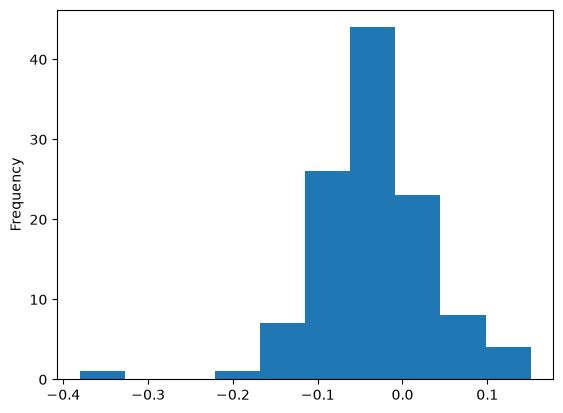

In [9]:
(us_prods.percentage_3 - australia_prods.percentage_3).plot.hist()

# Validation

How well does it work to estimate incidence by applying observed distribution 

In [21]:
# for every product estimate us incidence from australian one by using the differences of the remainder
margin_mult = norm.ppf(0.9)

preds = []

for prod in eligible_products:
    train_products = [x for x in eligible_products if x != prod]
    us_prods = df[df.product_category.isin(train_products) & 
        (df.geography_name=="United States")
    ].set_index("product_category")
    au_prods = df[df.product_category.isin(train_products) & 
        (df.geography_name=="Australia")
    ].set_index("product_category")
    diffs = (us_prods.percentage_3 - au_prods.percentage_3)
    mu = diffs.mean()
    pred = df[(df.product_category == prod) & 
        (df.geography_name=="Australia")
    ].percentage_3.iloc[0] + mu 
    u80 = diffs.quantile(.9) + mu
    l80 = diffs.quantile(.1) + mu
    preds.append(
        {"prod": prod,
         "point_estimate":pred,
         "true": df[(df.product_category == prod) & 
            (df.geography_name=="United States")
        ].percentage_3.iloc[0],
         "lower_80":l80,
         "upper_80":u80}
    )
preds = pd.DataFrame(preds)

<Axes: ylabel='Frequency'>

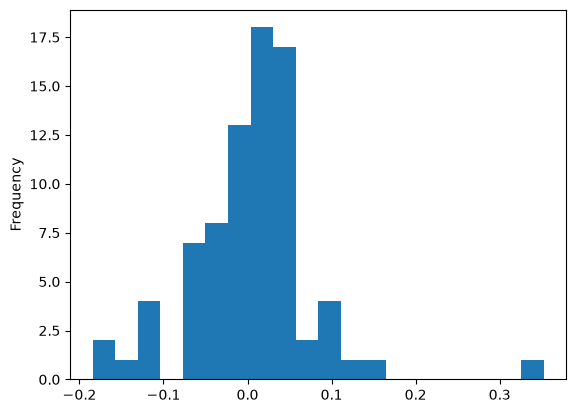

In [22]:
preds["residual"] = preds["true"] - preds["point_estimate"]
preds.residual.plot.hist(bins=20)

In [23]:
preds.residual.describe()

count    79.000000
mean      0.003743
std       0.073738
min      -0.184143
25%      -0.028918
50%       0.013340
75%       0.038323
max       0.352262
Name: residual, dtype: float64

### Estimate the confidence interval based on validation residuals

In [24]:
preds.residual.quantile([.1,.9])

0.1   -0.073422
0.9    0.058228
Name: residual, dtype: float64

In [26]:
(preds.upper_80-preds.lower_80).describe()

count    79.000000
mean      0.158532
std       0.006568
min       0.146195
25%       0.156516
50%       0.161353
75%       0.161353
max       0.169086
dtype: float64

Estimated intervals for each prediction are slightly larger than the residuals. I have to think about this...

# Apply to Air Conditioner

In [37]:
prod = "Air Conditioners"

us_prods = df[df.product_category.isin(eligible_products) & 
    (df.geography_name=="United States")
].set_index("product_category")
au_prods = df[df.product_category.isin(eligible_products) & 
    (df.geography_name=="Australia")
].set_index("product_category")
diffs = (us_prods.percentage_3 - au_prods.percentage_3)
mu = diffs.mean()
row = df[(df.product_category == prod) & 
        (df.geography_name=="Australia")
    ].iloc[0]
incidence_uncert = ((row.percentage_3*(1-row.percentage_3))**.5 / row.base_weight_3**.5)

pred = row.percentage_3 + mu 
u80 = diffs.quantile(.9) + pred
l80 = diffs.quantile(.1) + pred
print(f"Questionaire about Air conditioners in the US expected to have an incidence of {pred:.2f} (between {l80:.2f} and {u80:.2f} with 80% confidence)")

Questionaire about Air conditioners in the US expected to have an incidence of 0.38 (between 0.32 and 0.48 with 80% confidence)


In [38]:
row

category_name                                             Air Conditioners
geography_name                                                   Australia
wave_date                                                       2024-09-01
question_text            In the past 2 years have you purchased an air ...
qualifying_options       No, but I am open or likely to in the near fut...
disqualifying_options                                                   No
weight_3                                                            681.01
base_weight_3                                                      1966.48
percentage_3                                                       0.34631
timeframe_months                                                      24.0
have_you_quest                                                        True
are_you_quest                                                        False
multi_choice_quest                                                   False
do_you_own_quest         

In [40]:
incidence_uncert = ((row.percentage_3*(1-row.percentage_3))**.5 / row.base_weight_3**.5)

margin_mult = norm.ppf(0.90)
logit_uncert = logit(incidence_uncert*margin_mult + row.percentage_3 ) - logit(-incidence_uncert*margin_mult + row.percentage_3 )
logit_uncert

np.float64(0.12152744227566192)

In [41]:
incidence_uncert

np.float64(0.010729356358261982)